# 🎮 VALORANT Personal Coach

## CatBoost — Role-Aware Personalized Agent Recommendation

This standalone notebook trains and evaluates **only CatBoost**.

The model estimates:

**P(Win | Map, Candidate Agent, Role, Historical Player Features)**

Only historical information available before each target match is used.

The final recommendation layer is role-aware and returns up to **two agents
within each role**.

The notebook currently points to **Tanishka's dataset**.


In [1]:
%pip install -q catboost scikit-learn pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import ParameterGrid
from time import perf_counter

from catboost import CatBoostClassifier


In [3]:

# ============================================================
# DATASET CONFIGURATION
# ============================================================
# This notebook currently points to Tanishka's dataset.
#
# To reuse the SAME notebook for another standardized player
# dataset later, only change the values in this configuration
# block. The modelling code below does not need to be rewritten.

PLAYER_NAME = "Tanishka"
RESULT_PREFIX = "tanishka"

UPDATED_RAW_FILENAME = "competitive_matches_role_updated.xlsx"
CLEANED_FILENAME = "competitive_matches_cleaned.csv"
FEATURE_FILENAME = "competitive_matches_features.csv"


# ============================================================
# PROJECT PATHS
# ============================================================

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name in [
    "notebooks",
    "DEVnotebooks",
    "model_notebooks"
]:
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_DIR = PROJECT_ROOT / "data"
UPDATED_DIR = DATA_DIR / "updated"
RESULTS_DIR = PROJECT_ROOT / "results"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

UPDATED_DATA_PATH = (
    UPDATED_DIR / UPDATED_RAW_FILENAME
)

CLEANED_PATH = (
    UPDATED_DIR / CLEANED_FILENAME
)

FEATURE_PATH = (
    UPDATED_DIR / FEATURE_FILENAME
)

print("Player:", PLAYER_NAME)
print("Project root:", PROJECT_ROOT)
print("Updated raw dataset:", UPDATED_DATA_PATH)
print("Cleaned dataset:", CLEANED_PATH)
print("Feature dataset:", FEATURE_PATH)


Player: Tanishka
Project root: c:\Users\HP\Desktop\valorant_personal_coach
Updated raw dataset: c:\Users\HP\Desktop\valorant_personal_coach\data\updated\competitive_matches_role_updated.xlsx
Cleaned dataset: c:\Users\HP\Desktop\valorant_personal_coach\data\updated\competitive_matches_cleaned.csv
Feature dataset: c:\Users\HP\Desktop\valorant_personal_coach\data\updated\competitive_matches_features.csv


In [4]:

# ============================================================
# LOAD DATA
# ============================================================

features_df = pd.read_csv(
    FEATURE_PATH,
    parse_dates=["Date"]
)

cleaned_df = pd.read_csv(
    CLEANED_PATH,
    parse_dates=["Date"]
)

features_df = (
    features_df
    .sort_values(["Date", "Match id"])
    .reset_index(drop=True)
)

cleaned_df = (
    cleaned_df
    .sort_values(["Date", "Match id"])
    .reset_index(drop=True)
)

print("Feature dataset shape:", features_df.shape)
print("Cleaned dataset shape:", cleaned_df.shape)


Feature dataset shape: (304, 36)
Cleaned dataset shape: (304, 26)


In [5]:
# ============================================================
# ROLE-AWARE HISTORICAL FEATURES
# ============================================================

AGENT_ROLE_MAP = {
    # Duelists
    "Iso": "Duelist",
    "Jett": "Duelist",
    "Neon": "Duelist",
    "Phoenix": "Duelist",
    "Raze": "Duelist",
    "Reyna": "Duelist",
    "Waylay": "Duelist",
    "Yoru": "Duelist",

    # Controllers
    "Astra": "Controller",
    "Brimstone": "Controller",
    "Clove": "Controller",
    "Harbor": "Controller",
    "Miks": "Controller",
    "Omen": "Controller",
    "Viper": "Controller",

    # Initiators
    "Breach": "Initiator",
    "Fade": "Initiator",
    "Gekko": "Initiator",
    "KAY/O": "Initiator",
    "Skye": "Initiator",
    "Sova": "Initiator",
    "Tejo": "Initiator",

    # Sentinels
    "Chamber": "Sentinel",
    "Cypher": "Sentinel",
    "Deadlock": "Sentinel",
    "Killjoy": "Sentinel",
    "Sage": "Sentinel",
    "Veto": "Sentinel",
    "Vyse": "Sentinel",
}


def get_agent_role(agent):
    """Return the official role for an agent."""
    return AGENT_ROLE_MAP.get(agent, "Unknown")


# Ensure Role exists in both dataframes.
cleaned_df["Role"] = (
    cleaned_df["Agent"]
    .map(AGENT_ROLE_MAP)
)

features_df["Role"] = (
    features_df["Agent"]
    .map(AGENT_ROLE_MAP)
)


# ------------------------------------------------------------
# Historical role-level features
# ------------------------------------------------------------

_role_df = cleaned_df.copy()

_role_df["Win Flag"] = pd.to_numeric(
    _role_df["Win Flag"],
    errors="coerce"
)

_role_df["Kills"] = pd.to_numeric(
    _role_df["Kills"],
    errors="coerce"
)

_role_df["Deaths"] = pd.to_numeric(
    _role_df["Deaths"],
    errors="coerce"
)

_role_df["ACS"] = pd.to_numeric(
    _role_df["ACS"],
    errors="coerce"
)


_role_df["role_previous_matches"] = (
    _role_df
    .groupby("Role")
    .cumcount()
)


_role_df["role_previous_win_rate"] = (
    _role_df
    .groupby("Role")["Win Flag"]
    .transform(
        lambda s:
        s.shift(1).expanding().mean()
    )
)


role_previous_kills = (
    _role_df
    .groupby("Role")["Kills"]
    .cumsum()
    - _role_df["Kills"]
)

role_previous_deaths = (
    _role_df
    .groupby("Role")["Deaths"]
    .cumsum()
    - _role_df["Deaths"]
)

_role_df["role_previous_kd"] = (
    role_previous_kills
    / role_previous_deaths.replace(0, np.nan)
)


_role_df["role_previous_acs"] = (
    _role_df
    .groupby("Role")["ACS"]
    .transform(
        lambda s:
        s.shift(1).expanding().mean()
    )
)


_role_df["role_usage_frequency"] = (
    _role_df["role_previous_matches"]
    / features_df["previous_matches"].replace(0, np.nan)
)


role_feature_columns = [
    "Match id",
    "role_previous_matches",
    "role_previous_win_rate",
    "role_previous_kd",
    "role_previous_acs",
    "role_usage_frequency"
]


features_df = (
    features_df
    .drop(
        columns=[
            c for c in role_feature_columns
            if c != "Match id" and c in features_df.columns
        ],
        errors="ignore"
    )
    .merge(
        _role_df[role_feature_columns],
        on="Match id",
        how="left"
    )
)


# Agent ACS relative to the player's historical role ACS.
features_df["agent_role_acs_delta"] = (
    features_df["agent_previous_acs"]
    - features_df["role_previous_acs"]
)


print(
    "Roles:",
    cleaned_df["Role"].value_counts().to_dict()
)

print(
    "Role-aware features added:",
    [
        "Role",
        "role_previous_matches",
        "role_previous_win_rate",
        "role_previous_kd",
        "role_previous_acs",
        "role_usage_frequency",
        "agent_role_acs_delta"
    ]
)


Roles: {'Sentinel': 205, 'Controller': 65, 'Initiator': 31, 'Duelist': 3}
Role-aware features added: ['Role', 'role_previous_matches', 'role_previous_win_rate', 'role_previous_kd', 'role_previous_acs', 'role_usage_frequency', 'agent_role_acs_delta']


In [6]:

print("Results:")
print(
    features_df["Result"]
    .value_counts()
)

print("\nWin Flag:")
print(
    features_df["Win Flag"]
    .value_counts(dropna=False)
)


Results:
Result
Loss    152
Win     142
Draw     10
Name: count, dtype: int64

Win Flag:
Win Flag
0.0    152
1.0    142
NaN     10
Name: count, dtype: int64



## Model Input Features

Only information available **before the target match** is used as model input.

Current-match K/D, ACS, kills, deaths, DDΔ, final scores, and match-ending
information are excluded to prevent data leakage.

The model uses the candidate agent's `Role` together with chronological
historical information including:

- previous overall performance,
- recent 5-match and 10-match form,
- previous agent performance,
- previous map performance,
- previous Agent × Map performance,
- agent familiarity, frequency, and recency,
- previous role matches,
- previous role win rate,
- previous role K/D,
- previous role ACS,
- role usage frequency,
- and `agent_role_acs_delta`.

The official role is determined by the agent. ACS is used only as a historical
performance signal.


In [7]:
# ============================================================
# MODEL FEATURES
# ============================================================

categorical_features = [
    "Map",
    "Agent",
    "Role",
    "agent_familiarity"
]


numeric_features = [
    "previous_matches",
    "previous_win_rate",
    "previous_kd",

    "recent_5_win_rate",
    "recent_10_win_rate",
    "recent_5_kd",
    "recent_10_kd",
    "recent_5_acs",
    "recent_10_acs",

    "agent_previous_matches",
    "agent_previous_win_rate",
    "agent_previous_kd",
    "agent_previous_acs",

    "map_previous_matches",
    "map_previous_win_rate",
    "map_previous_kd",

    "agent_map_previous_matches",
    "agent_map_previous_win_rate",
    "agent_map_previous_kd",

    "agent_usage_frequency",
    "agent_recency",

    # Role-aware historical features
    "role_previous_matches",
    "role_previous_win_rate",
    "role_previous_kd",
    "role_previous_acs",
    "role_usage_frequency",

    # Agent ACS compared with historical ACS for that role
    "agent_role_acs_delta"
]


model_features = (
    categorical_features
    + numeric_features
)


print(
    "Number of model features:",
    len(model_features)
)

print("\nCategorical:")
print(categorical_features)

print("\nNumerical:")
print(numeric_features)


Number of model features: 31

Categorical:
['Map', 'Agent', 'Role', 'agent_familiarity']

Numerical:
['previous_matches', 'previous_win_rate', 'previous_kd', 'recent_5_win_rate', 'recent_10_win_rate', 'recent_5_kd', 'recent_10_kd', 'recent_5_acs', 'recent_10_acs', 'agent_previous_matches', 'agent_previous_win_rate', 'agent_previous_kd', 'agent_previous_acs', 'map_previous_matches', 'map_previous_win_rate', 'map_previous_kd', 'agent_map_previous_matches', 'agent_map_previous_win_rate', 'agent_map_previous_kd', 'agent_usage_frequency', 'agent_recency', 'role_previous_matches', 'role_previous_win_rate', 'role_previous_kd', 'role_previous_acs', 'role_usage_frequency', 'agent_role_acs_delta']


In [8]:
# ============================================================
# BINARY MODELLING DATA
# ============================================================

model_df = (
    features_df[
        features_df["Win Flag"].notna()
    ]
    .copy()
    .reset_index(drop=True)
)


X = model_df[
    model_features
].copy()

y = (
    model_df["Win Flag"]
    .astype(int)
)


print(
    "Binary modelling rows:",
    len(model_df)
)

print("\nTarget distribution:")
print(y.value_counts())

Binary modelling rows: 294

Target distribution:
Win Flag
0    152
1    142
Name: count, dtype: int64



## Chronological Data Split

A random split is not used because the project represents sequential gameplay.

Older matches are used to learn player behaviour, while newer matches are kept
for validation and testing.

The chronological split is:

- **70% Training**
- **15% Validation**
- **15% Testing**

This prevents future matches from influencing a model trained on earlier
gameplay history.


In [9]:
# ============================================================
# CHRONOLOGICAL SPLIT
# ============================================================

n = len(model_df)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)


train_df = model_df.iloc[
    :train_end
].copy()

validation_df = model_df.iloc[
    train_end:validation_end
].copy()

test_df = model_df.iloc[
    validation_end:
].copy()


X_train = train_df[model_features]
y_train = train_df["Win Flag"].astype(int)

X_validation = validation_df[model_features]
y_validation = validation_df["Win Flag"].astype(int)

X_test = test_df[model_features]
y_test = test_df["Win Flag"].astype(int)


print(
    "Training matches:",
    len(train_df)
)

print(
    "Validation matches:",
    len(validation_df)
)

print(
    "Testing matches:",
    len(test_df)
)


print(
    "\nTraining period:",
    train_df["Date"].min(),
    "to",
    train_df["Date"].max()
)

print(
    "\nValidation period:",
    validation_df["Date"].min(),
    "to",
    validation_df["Date"].max()
)

print(
    "\nTesting period:",
    test_df["Date"].min(),
    "to",
    test_df["Date"].max()
)

Training matches: 205
Validation matches: 44
Testing matches: 45

Training period: 2024-11-07 00:00:00 to 2025-06-25 00:00:00

Validation period: 2025-06-25 00:00:00 to 2026-08-11 00:00:00

Testing period: 2026-08-11 00:00:00 to 2026-09-27 00:00:00


In [10]:

MODEL_NAME = "CatBoost"
MODEL_SLUG = "catboost"

# ============================================================
# CATBOOST DATA PREPARATION
# ============================================================

def prepare_catboost_data(
    X,
    numeric_fill_values=None
):
    data = X.copy()

    for column in categorical_features:
        data[column] = (
            data[column]
            .astype("string")
            .fillna("Unknown")
            .astype(str)
        )

    if numeric_fill_values is None:
        numeric_fill_values = (
            data[numeric_features]
            .median()
        )

    data[numeric_features] = (
        data[numeric_features]
        .fillna(numeric_fill_values)
    )

    return data, numeric_fill_values


def fit_model_with_params(
    params,
    X_fit,
    y_fit
):
    X_fit_cat, numeric_fill_values = (
        prepare_catboost_data(
            X_fit
        )
    )

    cat_feature_indices = [
        X_fit_cat.columns.get_loc(column)
        for column in categorical_features
    ]

    model = CatBoostClassifier(
        iterations=params["iterations"],
        depth=params["depth"],
        learning_rate=(
            params["learning_rate"]
        ),
        l2_leaf_reg=(
            params["l2_leaf_reg"]
        ),
        loss_function="Logloss",
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    )

    model.fit(
        X_fit_cat,
        y_fit,
        cat_features=cat_feature_indices,
        verbose=False
    )

    # Store training medians so every future prediction uses
    # values learned from the model's own fitting data.
    model._numeric_fill_values = (
        numeric_fill_values
    )

    return model


def predict_win_probability(
    model_name,
    model,
    X_data
):
    numeric_fill_values = getattr(
        model,
        "_numeric_fill_values",
        None
    )

    if numeric_fill_values is None:
        raise ValueError(
            "CatBoost training fill values "
            "were not stored."
        )

    prepared, _ = prepare_catboost_data(
        X_data,
        numeric_fill_values=(
            numeric_fill_values
        )
    )

    return (
        model.predict_proba(
            prepared
        )[:, 1]
    )

param_grid = {
    "iterations": [
        200
    ],
    "depth": [
        3,
        4
    ],
    "learning_rate": [
        0.03,
        0.05
    ],
    "l2_leaf_reg": [
        3,
        5
    ]
}

baseline_params = {
    "iterations": 200,
    "depth": 4,
    "learning_rate": 0.05,
    "l2_leaf_reg": 3
}


In [11]:
# ============================================================
# HISTORICAL HELPERS
# ============================================================

def historical_win_rate(history):
    """
    Win rate using Win/Loss matches.
    Draw Win Flags are NaN and therefore ignored.
    """

    if len(history) == 0:
        return np.nan

    values = pd.to_numeric(
        history["Win Flag"],
        errors="coerce"
    ).dropna()

    if len(values) == 0:
        return np.nan

    return values.mean()


def historical_kd(history):
    """
    Aggregate K/D:
    total kills / total deaths
    """

    if len(history) == 0:
        return np.nan

    kills = pd.to_numeric(
        history["Kills"],
        errors="coerce"
    ).sum()

    deaths = pd.to_numeric(
        history["Deaths"],
        errors="coerce"
    ).sum()

    if deaths == 0:
        return np.nan

    return kills / deaths


def historical_acs(history):
    """
    Mean historical ACS.
    """

    if len(history) == 0:
        return np.nan

    values = pd.to_numeric(
        history["ACS"],
        errors="coerce"
    ).dropna()

    if len(values) == 0:
        return np.nan

    return values.mean()


def familiarity_level(matches):

    if matches == 0:
        return "New"

    if matches < 5:
        return "Very Low"

    if matches < 15:
        return "Low"

    if matches < 40:
        return "Medium"

    return "High"


In [12]:
# ============================================================
# BUILD ONE CANDIDATE AGENT PROFILE
# ============================================================

def build_candidate_profile(
    history,
    current_map,
    candidate_agent
):
    """
    Construct a leakage-free pre-match profile for one candidate agent.
    """

    history = history.copy()

    if "Role" not in history.columns:
        history["Role"] = (
            history["Agent"]
            .map(AGENT_ROLE_MAP)
        )

    previous_matches = len(history)
    candidate_role = get_agent_role(candidate_agent)


    # --------------------------------------------------------
    # Overall player history
    # --------------------------------------------------------

    previous_win_rate = historical_win_rate(history)
    previous_kd = historical_kd(history)


    # --------------------------------------------------------
    # Recent history
    # --------------------------------------------------------

    recent_5 = history.tail(5)
    recent_10 = history.tail(10)

    recent_5_win_rate = historical_win_rate(recent_5)
    recent_10_win_rate = historical_win_rate(recent_10)

    recent_5_kd = historical_kd(recent_5)
    recent_10_kd = historical_kd(recent_10)

    recent_5_acs = historical_acs(recent_5)
    recent_10_acs = historical_acs(recent_10)


    # --------------------------------------------------------
    # Agent history
    # --------------------------------------------------------

    agent_history = history[
        history["Agent"] == candidate_agent
    ]

    agent_previous_matches = len(agent_history)
    agent_previous_win_rate = historical_win_rate(agent_history)
    agent_previous_kd = historical_kd(agent_history)
    agent_previous_acs = historical_acs(agent_history)


    # --------------------------------------------------------
    # Map history
    # --------------------------------------------------------

    map_history = history[
        history["Map"] == current_map
    ]

    map_previous_matches = len(map_history)
    map_previous_win_rate = historical_win_rate(map_history)
    map_previous_kd = historical_kd(map_history)


    # --------------------------------------------------------
    # Agent × Map history
    # --------------------------------------------------------

    agent_map_history = history[
        (history["Agent"] == candidate_agent)
        &
        (history["Map"] == current_map)
    ]

    agent_map_previous_matches = len(agent_map_history)
    agent_map_previous_win_rate = historical_win_rate(agent_map_history)
    agent_map_previous_kd = historical_kd(agent_map_history)


    # --------------------------------------------------------
    # Agent familiarity / recency
    # --------------------------------------------------------

    agent_usage_frequency = (
        agent_previous_matches / previous_matches
        if previous_matches > 0
        else np.nan
    )

    if len(agent_history) > 0:
        last_agent_index = agent_history.index[-1]
        current_index = history.index[-1] + 1

        agent_recency = (
            current_index
            - last_agent_index
        )
    else:
        agent_recency = np.nan


    # --------------------------------------------------------
    # Role history
    # --------------------------------------------------------

    role_history = history[
        history["Role"] == candidate_role
    ]

    role_previous_matches = len(role_history)
    role_previous_win_rate = historical_win_rate(role_history)
    role_previous_kd = historical_kd(role_history)
    role_previous_acs = historical_acs(role_history)

    role_usage_frequency = (
        role_previous_matches / previous_matches
        if previous_matches > 0
        else np.nan
    )


    # --------------------------------------------------------
    # Agent + Role ACS relationship
    # --------------------------------------------------------

    if (
        pd.notna(agent_previous_acs)
        and
        pd.notna(role_previous_acs)
    ):
        agent_role_acs_delta = (
            agent_previous_acs
            - role_previous_acs
        )
    else:
        agent_role_acs_delta = np.nan


    profile = {
        "Map": current_map,
        "Agent": candidate_agent,
        "Role": candidate_role,

        "previous_matches": previous_matches,
        "previous_win_rate": previous_win_rate,
        "previous_kd": previous_kd,

        "recent_5_win_rate": recent_5_win_rate,
        "recent_10_win_rate": recent_10_win_rate,
        "recent_5_kd": recent_5_kd,
        "recent_10_kd": recent_10_kd,
        "recent_5_acs": recent_5_acs,
        "recent_10_acs": recent_10_acs,

        "agent_previous_matches": agent_previous_matches,
        "agent_previous_win_rate": agent_previous_win_rate,
        "agent_previous_kd": agent_previous_kd,
        "agent_previous_acs": agent_previous_acs,

        "map_previous_matches": map_previous_matches,
        "map_previous_win_rate": map_previous_win_rate,
        "map_previous_kd": map_previous_kd,

        "agent_map_previous_matches": agent_map_previous_matches,
        "agent_map_previous_win_rate": agent_map_previous_win_rate,
        "agent_map_previous_kd": agent_map_previous_kd,

        "agent_usage_frequency": agent_usage_frequency,
        "agent_recency": agent_recency,
        "agent_familiarity": familiarity_level(
            agent_previous_matches
        ),

        "role_previous_matches": role_previous_matches,
        "role_previous_win_rate": role_previous_win_rate,
        "role_previous_kd": role_previous_kd,
        "role_previous_acs": role_previous_acs,
        "role_usage_frequency": role_usage_frequency,

        "agent_role_acs_delta": agent_role_acs_delta
    }

    return profile


In [13]:
# ============================================================
# CANDIDATE AGENT GENERATION
# ============================================================

def build_candidate_table(
    history,
    current_map,
    min_previous_matches=1
):
    """
    Build one feature row for every agent the player has
    previously used.
    """

    agent_counts = (
        history["Agent"]
        .value_counts()
    )


    candidate_agents = (
        agent_counts[
            agent_counts
            >= min_previous_matches
        ]
        .index
        .tolist()
    )


    profiles = []


    for agent in candidate_agents:

        profile = build_candidate_profile(
            history=history,
            current_map=current_map,
            candidate_agent=agent
        )

        profiles.append(profile)


    return pd.DataFrame(profiles)

In [14]:
# ============================================================
# ROLE-AWARE AGENT RANKING
# ============================================================

def rank_agents_by_role(
    model_name,
    model,
    history,
    current_map,
    top_per_role=2
):
    """
    Rank candidate agents by predicted win probability and return
    up to Top-N agents inside each role.

    Roles are ordered by the player's historical role usage.
    """

    history = history.copy()

    if "Role" not in history.columns:
        history["Role"] = (
            history["Agent"]
            .map(AGENT_ROLE_MAP)
        )

    candidates = build_candidate_table(
        history=history,
        current_map=current_map,
        min_previous_matches=1
    )

    if candidates.empty:
        return candidates

    probabilities = predict_win_probability(
        model_name,
        model,
        candidates[model_features]
    )

    candidates[
        "Predicted Win Probability"
    ] = probabilities


    role_order = (
        history["Role"]
        .value_counts()
        .index
        .tolist()
    )

    role_priority = {
        role: position
        for position, role
        in enumerate(role_order)
    }

    candidates["_role_priority"] = (
        candidates["Role"]
        .map(role_priority)
        .fillna(len(role_priority))
    )


    ranked = (
        candidates
        .sort_values(
            [
                "_role_priority",
                "Role",
                "Predicted Win Probability"
            ],
            ascending=[
                True,
                True,
                False
            ]
        )
        .groupby(
            "Role",
            sort=False,
            group_keys=False
        )
        .head(top_per_role)
        .copy()
    )


    ranked["Role Rank"] = (
        ranked
        .groupby("Role")
        .cumcount()
        + 1
    )


    ranked = (
        ranked[
            [
                "Role",
                "Role Rank",
                "Agent",
                "Predicted Win Probability",
                "role_usage_frequency",
                "role_previous_matches",
                "role_previous_win_rate",
                "role_previous_acs",
                "agent_previous_matches",
                "agent_previous_win_rate",
                "agent_previous_acs",
                "agent_role_acs_delta",
                "agent_familiarity"
            ]
        ]
        .reset_index(drop=True)
    )

    return ranked


In [15]:
# ============================================================
# RETROSPECTIVE RANKING EVALUATION
# ============================================================

def evaluate_ranking(
    model_name,
    model,
    cleaned_history,
    evaluation_match_ids,
    top_k_values=(5, 6)
):
    """
    Retrospective ranking evaluation.

    For every historical match:
    1. Use ONLY history before that match.
    2. Generate candidate agents.
    3. Rank them.
    4. Check where the agent actually played appears.

    Matches where the played agent had never previously been
    used are skipped because that agent was not part of the
    known historical agent pool.
    """

    reciprocal_ranks = []

    hit_counts = {
        k: 0
        for k in top_k_values
    }

    evaluated = 0


    for match_id in evaluation_match_ids:

        matching_rows = cleaned_history[
            cleaned_history["Match id"]
            == match_id
        ]

        if matching_rows.empty:
            continue


        row_index = (
            matching_rows.index[0]
        )

        current_row = (
            cleaned_history.loc[
                row_index
            ]
        )


        history = (
            cleaned_history.iloc[
                :row_index
            ]
            .copy()
        )


        actual_agent = (
            current_row["Agent"]
        )

        current_map = (
            current_row["Map"]
        )


        # Can't evaluate first-time agent use because
        # recommender only considers previously used agents.
        if actual_agent not in history["Agent"].values:
            continue


        candidates = build_candidate_table(
            history=history,
            current_map=current_map,
            min_previous_matches=1
        )


        if candidates.empty:
            continue


        probabilities = (
            predict_win_probability(
                model_name,
                model,
                candidates[model_features]
            )
        )


        candidates[
            "probability"
        ] = probabilities


        candidates = (
            candidates
            .sort_values(
                "probability",
                ascending=False
            )
            .reset_index(drop=True)
        )


        matches = candidates.index[
            candidates["Agent"]
            == actual_agent
        ].tolist()


        if not matches:
            continue


        actual_rank = (
            matches[0] + 1
        )


        reciprocal_ranks.append(
            1 / actual_rank
        )


        for k in top_k_values:

            if actual_rank <= k:
                hit_counts[k] += 1


        evaluated += 1


    results = {
        "Model": model_name,
        "Evaluated Matches": evaluated,
        "MRR": (
            np.mean(reciprocal_ranks)
            if reciprocal_ranks
            else np.nan
        )
    }


    for k in top_k_values:

        results[f"Hit@{k}"] = (
            hit_counts[k] / evaluated
            if evaluated > 0
            else np.nan
        )


    return results


## Ranking Evaluation Limitation

The historical dataset records the outcome only for the agent that was actually
selected in each match.

It does not contain counterfactual outcomes showing what would have happened if
a different agent had been selected in the same match.

Therefore, **Hit@5, Hit@6, and MRR** are used as retrospective ranking proxies.
They measure how highly the model ranks the historically selected agent using
only information available before that match.

These metrics evaluate the raw candidate ranking. The final user-facing
recommendation layer is separate and returns up to **two agents per role**.

The metrics do not prove that the historically selected agent was objectively
the best possible agent.


# Baseline CatBoost

A baseline CatBoost model is first trained on the chronological training
period and evaluated retrospectively on the validation period. This provides a
reference before hyperparameter optimization.


In [16]:

# ============================================================
# BASELINE MODEL
# ============================================================

baseline_model = fit_model_with_params(
    baseline_params,
    X_train,
    y_train
)

validation_match_ids = (
    validation_df["Match id"]
    .tolist()
)

baseline_validation_result = (
    evaluate_ranking(
        MODEL_NAME,
        baseline_model,
        cleaned_df,
        validation_match_ids
    )
)

pd.DataFrame(
    [baseline_validation_result]
)


,Model,Evaluated Matches,MRR,Hit@5,Hit@6
0,CatBoost,44,0.267487,0.613636,0.75


# Hyperparameter Optimization

Only **CatBoost** is tuned in this notebook.

The original training period is divided chronologically again:

- earlier training matches fit each candidate configuration,
- the newest part of the training period acts as an internal tuning set.

The external validation and held-out test periods remain excluded from
hyperparameter selection.

Hyperparameters are selected primarily using **Hit@6**, with **MRR** as the
tie-breaker, matching the ranking procedure used in the original combined
notebook.


In [17]:

# ============================================================
# INTERNAL CHRONOLOGICAL SPLIT FOR HYPERPARAMETER TUNING
# ============================================================

tuning_split_index = int(
    len(train_df) * 0.80
)

tune_train_df = (
    train_df.iloc[:tuning_split_index]
    .copy()
)

tune_holdout_df = (
    train_df.iloc[tuning_split_index:]
    .copy()
)

X_tune_train = (
    tune_train_df[model_features]
)

y_tune_train = (
    tune_train_df["Win Flag"]
    .astype(int)
)

tune_match_ids = (
    tune_holdout_df["Match id"]
    .tolist()
)

print(f"{PLAYER_NAME} Hyperparameter Tuning Split")
print("\nModel-fitting matches:", len(tune_train_df))
print("Internal tuning matches:", len(tune_holdout_df))

print(
    "\nModel-fitting period:",
    tune_train_df["Date"].min(),
    "to",
    tune_train_df["Date"].max()
)

print(
    "\nTuning period:",
    tune_holdout_df["Date"].min(),
    "to",
    tune_holdout_df["Date"].max()
)


Tanishka Hyperparameter Tuning Split

Model-fitting matches: 164
Internal tuning matches: 41

Model-fitting period: 2024-11-07 00:00:00 to 2025-05-09 00:00:00

Tuning period: 2025-05-09 00:00:00 to 2025-06-25 00:00:00


In [18]:

# ============================================================
# RANKING-BASED HYPERPARAMETER TUNING
# ============================================================

def tune_model(
    param_grid
):
    tuning_records = []

    best_model = None
    best_params = None
    best_hit6 = -1
    best_mrr = -1

    combinations = list(
        ParameterGrid(param_grid)
    )

    print(f"\nTuning {MODEL_NAME}")
    print(
        "Number of combinations:",
        len(combinations)
    )

    for number, params in enumerate(
        combinations,
        start=1
    ):
        print(
            f"\n{MODEL_NAME} "
            f"{number}/{len(combinations)}"
        )
        print(params)

        model = fit_model_with_params(
            params,
            X_tune_train,
            y_tune_train
        )

        ranking_result = evaluate_ranking(
            MODEL_NAME,
            model,
            cleaned_df,
            tune_match_ids
        )

        hit6 = ranking_result["Hit@6"]
        mrr = ranking_result["MRR"]

        tuning_records.append(
            {
                "Model": MODEL_NAME,
                **params,
                "Evaluated Matches":
                    ranking_result["Evaluated Matches"],
                "MRR": mrr,
                "Hit@5": ranking_result["Hit@5"],
                "Hit@6": hit6
            }
        )

        print("Hit@6:", round(hit6, 4))
        print("MRR:", round(mrr, 4))

        # Primary tuning criterion: Hit@6
        # Tie-breaker: MRR
        if (
            hit6 > best_hit6
            or (
                hit6 == best_hit6
                and mrr > best_mrr
            )
        ):
            best_hit6 = hit6
            best_mrr = mrr
            best_model = model
            best_params = params.copy()

    tuning_df = (
        pd.DataFrame(tuning_records)
        .sort_values(
            by=["Hit@6", "MRR"],
            ascending=False
        )
        .reset_index(drop=True)
    )

    print(
        f"\nBest {MODEL_NAME} parameters:"
    )
    print(best_params)
    print(
        "Best tuning Hit@6:",
        round(best_hit6, 4)
    )
    print(
        "Best tuning MRR:",
        round(best_mrr, 4)
    )

    return (
        best_model,
        best_params,
        tuning_df
    )


In [19]:

(
    best_tuning_model,
    best_params,
    tuning_results
) = tune_model(
    param_grid
)

tuning_results



Tuning CatBoost
Number of combinations: 8

CatBoost 1/8
{'depth': 3, 'iterations': 200, 'l2_leaf_reg': 3, 'learning_rate': 0.03}
Hit@6: 0.35
MRR: 0.2066

CatBoost 2/8
{'depth': 3, 'iterations': 200, 'l2_leaf_reg': 3, 'learning_rate': 0.05}
Hit@6: 0.25
MRR: 0.2164

CatBoost 3/8
{'depth': 3, 'iterations': 200, 'l2_leaf_reg': 5, 'learning_rate': 0.03}
Hit@6: 0.275
MRR: 0.2033

CatBoost 4/8
{'depth': 3, 'iterations': 200, 'l2_leaf_reg': 5, 'learning_rate': 0.05}
Hit@6: 0.275
MRR: 0.2246

CatBoost 5/8
{'depth': 4, 'iterations': 200, 'l2_leaf_reg': 3, 'learning_rate': 0.03}
Hit@6: 0.325
MRR: 0.2254

CatBoost 6/8
{'depth': 4, 'iterations': 200, 'l2_leaf_reg': 3, 'learning_rate': 0.05}
Hit@6: 0.275
MRR: 0.2111

CatBoost 7/8
{'depth': 4, 'iterations': 200, 'l2_leaf_reg': 5, 'learning_rate': 0.03}
Hit@6: 0.3
MRR: 0.209

CatBoost 8/8
{'depth': 4, 'iterations': 200, 'l2_leaf_reg': 5, 'learning_rate': 0.05}
Hit@6: 0.25
MRR: 0.1931

Best CatBoost parameters:
{'depth': 3, 'iterations': 200, 'l2_leaf

,Model,depth,iterations,l2_leaf_reg,learning_rate,Evaluated Matches,MRR,Hit@5,Hit@6
0,CatBoost,3,200,3,0.03,40,0.206567,0.250,0.350
1,CatBoost,4,200,3,0.03,40,0.225377,0.225,0.325
2,CatBoost,4,200,5,0.03,40,0.208968,0.250,0.300
3,CatBoost,3,200,5,0.05,40,0.224554,0.250,0.275
4,CatBoost,4,200,3,0.05,40,0.211141,0.275,0.275
5,CatBoost,3,200,5,0.03,40,0.203274,0.225,0.275
6,CatBoost,3,200,3,0.05,40,0.216389,0.250,0.250
7,CatBoost,4,200,5,0.05,40,0.193085,0.225,0.250


# Validation of Tuned CatBoost

The best hyperparameter configuration is retrained on the full 70% training
period and evaluated on the chronological 15% validation period.

Because this notebook contains only one algorithm, this validation step
evaluates the tuned CatBoost model rather than selecting between different
algorithms.


In [20]:

# ============================================================
# RETRAIN TUNED MODEL ON FULL TRAINING SET
# ============================================================

tuned_model = fit_model_with_params(
    best_params,
    X_train,
    y_train
)

validation_match_ids = (
    validation_df["Match id"]
    .tolist()
)

validation_result = evaluate_ranking(
    MODEL_NAME,
    tuned_model,
    cleaned_df,
    validation_match_ids
)

validation_results = pd.DataFrame(
    [validation_result]
)

validation_results


,Model,Evaluated Matches,MRR,Hit@5,Hit@6
0,CatBoost,44,0.256773,0.681818,0.886364


# Final Held-Out Test Evaluation

After tuning and validation, the model is retrained using the combined training and validation periods. The newest chronological matches remain reserved for final held-out testing.

In [21]:

# ============================================================
# COMBINE TRAIN + VALIDATION
# ============================================================

train_validation_df = (
    pd.concat(
        [train_df, validation_df],
        ignore_index=True
    )
)

X_train_validation = (
    train_validation_df[model_features]
)

y_train_validation = (
    train_validation_df["Win Flag"]
    .astype(int)
)

print(
    "Train + Validation rows:",
    len(train_validation_df)
)

print(
    "Held-out Test rows:",
    len(test_df)
)


Train + Validation rows: 249
Held-out Test rows: 45


In [22]:

# ============================================================
# FINAL MODEL
# ============================================================

final_model = fit_model_with_params(
    best_params,
    X_train_validation,
    y_train_validation
)

print("Final model retrained:")
print(MODEL_NAME)
print("\nSelected hyperparameters:")
print(best_params)


Final model retrained:
CatBoost

Selected hyperparameters:
{'depth': 3, 'iterations': 200, 'l2_leaf_reg': 3, 'learning_rate': 0.03}


In [23]:

# ============================================================
# FINAL HELD-OUT TEST EVALUATION
# ============================================================

test_match_ids = (
    test_df["Match id"]
    .tolist()
)

final_test_result = evaluate_ranking(
    MODEL_NAME,
    final_model,
    cleaned_df,
    test_match_ids
)

final_test_results = pd.DataFrame(
    [final_test_result]
)

final_test_results


,Model,Evaluated Matches,MRR,Hit@5,Hit@6
0,CatBoost,45,0.193351,0.266667,0.444444


# Model Interpretation

This section interprets the final **CatBoost** model.

Feature importance describes which historical variables the fitted model relies
on most strongly. It should not be interpreted as causal evidence.


In [24]:

# ============================================================
# CATBOOST FEATURE IMPORTANCE
# ============================================================

importances = (
    final_model
    .get_feature_importance()
)

feature_importance_df = pd.DataFrame(
    {
        "Feature": model_features,
        "Importance": importances
    }
)

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance_df.head(15)


,Feature,Importance
0,agent_previous_win_rate,7.494387
1,agent_familiarity,6.494067
2,role_previous_win_rate,6.394964
3,map_previous_kd,5.473406
4,Agent,5.288148
5,recent_5_acs,4.476416
6,agent_previous_acs,4.142259
7,agent_usage_frequency,3.876830
8,recent_10_kd,3.831401
9,recent_5_kd,3.662249


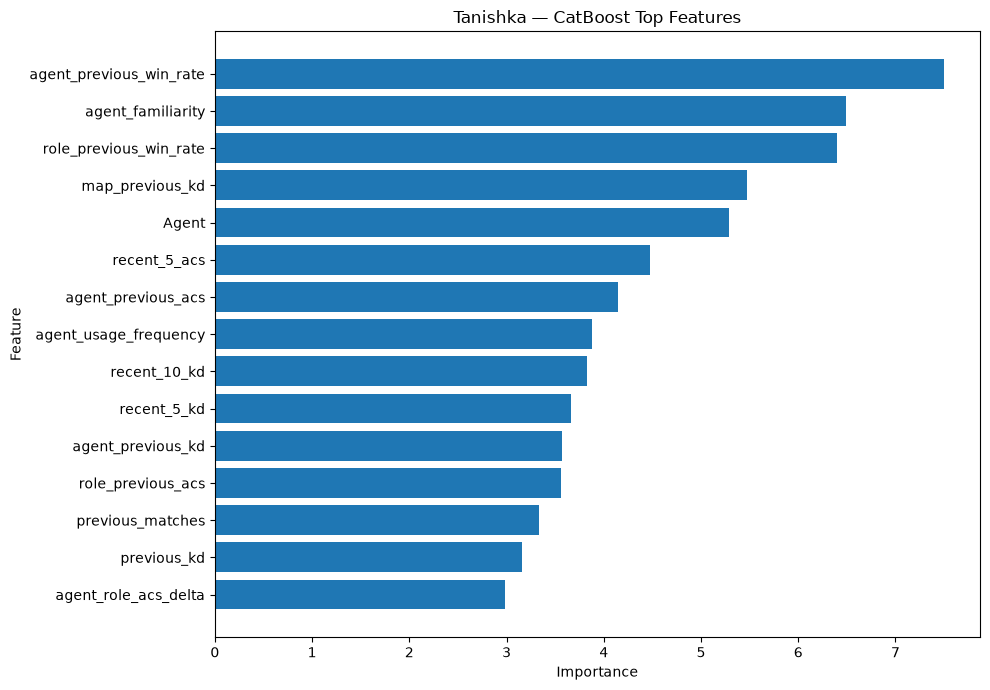

In [25]:

# ============================================================
# TOP FEATURE IMPORTANCE PLOT
# ============================================================

top_features = (
    feature_importance_df
    .head(15)
    .sort_values(
        "Importance",
        ascending=True
    )
)

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(
    f"{PLAYER_NAME} — "
    f"{MODEL_NAME} Top Features"
)
plt.tight_layout()
plt.show()


# Recommendation Runtime Evaluation

The final role-aware recommendation layer returns up to **two personalized agents per role** for a selected map. Runtime is measured across every map represented in the player's history.

In [26]:

# ============================================================
# RECOMMENDATION RUNTIME EVALUATION
# ============================================================

runtime_records = []

available_maps = sorted(
    cleaned_df["Map"]
    .dropna()
    .unique()
)

for current_map in available_maps:

    start_time = perf_counter()

    recommendations = rank_agents_by_role(
        model_name=MODEL_NAME,
        model=final_model,
        history=cleaned_df,
        current_map=current_map,
        top_per_role=2
    )

    end_time = perf_counter()

    runtime_records.append(
        {
            "Map": current_map,
            "Recommendation Time (seconds)":
                end_time - start_time,
            "Agents Returned":
                len(recommendations)
        }
    )

runtime_results = pd.DataFrame(
    runtime_records
)

runtime_results


,Map,Recommendation Time (seconds),Agents Returned
0,Abyss,0.133889,7
1,Ascent,0.139235,7
2,Bind,0.115499,7
3,Breeze,0.138128,7
4,Corrode,0.127125,7
5,Fracture,0.137243,7
6,Haven,0.130625,7
7,Icebox,0.126413,7
8,Lotus,0.150343,7
9,Pearl,0.138475,7


In [27]:

average_runtime = (
    runtime_results[
        "Recommendation Time (seconds)"
    ].mean()
)

maximum_runtime = (
    runtime_results[
        "Recommendation Time (seconds)"
    ].max()
)

minimum_runtime = (
    runtime_results[
        "Recommendation Time (seconds)"
    ].min()
)

requirement_met = (
    maximum_runtime <= 20
)

print(f"Player: {PLAYER_NAME}")
print(f"Model: {MODEL_NAME}")
print(
    f"Average recommendation time: "
    f"{average_runtime:.4f} seconds"
)
print(
    f"Minimum recommendation time: "
    f"{minimum_runtime:.4f} seconds"
)
print(
    f"Maximum recommendation time: "
    f"{maximum_runtime:.4f} seconds"
)

print(
    "\nSystem Requirement "
    "(maximum 20 seconds):",
    "PASSED"
    if requirement_met
    else "NOT PASSED"
)


Player: Tanishka
Model: CatBoost
Average recommendation time: 0.1326 seconds
Minimum recommendation time: 0.1131 seconds
Maximum recommendation time: 0.1503 seconds

System Requirement (maximum 20 seconds): PASSED


In [28]:

# ============================================================
# FINAL ROLE-AWARE RECOMMENDATION EXAMPLE
# ============================================================

CURRENT_MAP = "Haven"

final_recommendations = rank_agents_by_role(
    model_name=MODEL_NAME,
    model=final_model,
    history=cleaned_df,
    current_map=CURRENT_MAP,
    top_per_role=2
)

final_recommendations


,Role,Role Rank,Agent,Predicted Win Probability,role_usage_frequency,role_previous_matches,role_previous_win_rate,role_previous_acs,agent_previous_matches,agent_previous_win_rate,agent_previous_acs,agent_role_acs_delta,agent_familiarity
0,Sentinel,1,Killjoy,0.424949,0.674342,205,0.477387,158.214634,30,0.633333,169.566667,11.352033,Medium
1,Sentinel,2,Sage,0.321512,0.674342,205,0.477387,158.214634,164,0.468354,155.792683,-2.421951,High
2,Controller,1,Astra,0.483029,0.213816,65,0.507937,164.138462,6,0.833333,142.166667,-21.971795,Low
3,Controller,2,Clove,0.414958,0.213816,65,0.507937,164.138462,59,0.473684,166.372881,2.234420,High
4,Initiator,1,Breach,0.448520,0.101974,31,0.482759,160.838710,17,0.529412,157.470588,-3.368121,Medium
5,Initiator,2,Skye,0.426109,0.101974,31,0.482759,160.838710,9,0.375000,145.888889,-14.949821,Low
6,Duelist,1,Reyna,0.517390,0.009868,3,0.333333,154.666667,3,0.333333,154.666667,0.000000,Very Low


In [29]:

# ============================================================
# SAVE MODEL-SPECIFIC RESULTS
# ============================================================

tuning_results.to_csv(
    RESULTS_DIR
    / f"{RESULT_PREFIX}_{MODEL_SLUG}_hyperparameter_tuning.csv",
    index=False
)

validation_results.to_csv(
    RESULTS_DIR
    / f"{RESULT_PREFIX}_{MODEL_SLUG}_validation_results.csv",
    index=False
)

final_test_results.to_csv(
    RESULTS_DIR
    / f"{RESULT_PREFIX}_{MODEL_SLUG}_final_test_results.csv",
    index=False
)

feature_importance_df.to_csv(
    RESULTS_DIR
    / f"{RESULT_PREFIX}_{MODEL_SLUG}_feature_importance.csv",
    index=False
)

runtime_results.to_csv(
    RESULTS_DIR
    / f"{RESULT_PREFIX}_{MODEL_SLUG}_runtime_results.csv",
    index=False
)

final_recommendations.to_csv(
    RESULTS_DIR
    / (
        f"{RESULT_PREFIX}_{MODEL_SLUG}_"
        f"{CURRENT_MAP.lower()}_recommendations.csv"
    ),
    index=False
)

print("Saved result files for:", MODEL_NAME)


Saved result files for: CatBoost


# Final Interpretation

In [30]:

from IPython.display import display, Markdown

test_mrr = final_test_results.loc[0, "MRR"]
test_hit5 = final_test_results.loc[0, "Hit@5"]
test_hit6 = final_test_results.loc[0, "Hit@6"]

evaluated_matches = (
    final_test_results.loc[
        0,
        "Evaluated Matches"
    ]
)

top_feature_names = (
    feature_importance_df["Feature"]
    .head(5)
    .tolist()
)

top_feature_text = ", ".join(
    [
        f"**{feature}**"
        for feature in top_feature_names
    ]
)

runtime_status = (
    "satisfied"
    if requirement_met
    else "was not satisfied"
)

interpretation_text = f"""
# Final Model Interpretation

For **{PLAYER_NAME}**, this notebook trained and evaluated only the
**{MODEL_NAME}** algorithm.

Hyperparameters were selected using an internal chronological tuning period.
The external validation and held-out test periods were not used for
hyperparameter selection.

## Held-Out Test Performance

The model was evaluated on **{evaluated_matches} historical test matches**
that could be evaluated using the available candidate-agent history.

- **MRR:** {test_mrr:.4f}
- **Hit@5:** {test_hit5:.2%}
- **Hit@6:** {test_hit6:.2%}

Hit@5, Hit@6, and MRR evaluate the retrospective raw candidate ranking.
The final user-facing recommendation layer is role-aware and returns up to
**two agents per role**.

## Model Interpretation

The five most influential learned features were:

{top_feature_text}

Feature importance describes the behaviour of the trained model and should not
be interpreted as causal evidence.

## Runtime Performance

- **Average recommendation time:** {average_runtime:.4f} seconds
- **Maximum recommendation time:** {maximum_runtime:.4f} seconds

The project requirement of returning recommendations within approximately
**20 seconds** was therefore **{runtime_status}**.

Overall, this notebook demonstrates a complete, leakage-aware and
player-specific {MODEL_NAME} recommendation pipeline.
"""

display(
    Markdown(interpretation_text)
)



# Final Model Interpretation

For **Tanishka**, this notebook trained and evaluated only the
**CatBoost** algorithm.

Hyperparameters were selected using an internal chronological tuning period.
The external validation and held-out test periods were not used for
hyperparameter selection.

## Held-Out Test Performance

The model was evaluated on **45 historical test matches**
that could be evaluated using the available candidate-agent history.

- **MRR:** 0.1934
- **Hit@5:** 26.67%
- **Hit@6:** 44.44%

Hit@5, Hit@6, and MRR evaluate the retrospective raw candidate ranking.
The final user-facing recommendation layer is role-aware and returns up to
**two agents per role**.

## Model Interpretation

The five most influential learned features were:

**agent_previous_win_rate**, **agent_familiarity**, **role_previous_win_rate**, **map_previous_kd**, **Agent**

Feature importance describes the behaviour of the trained model and should not
be interpreted as causal evidence.

## Runtime Performance

- **Average recommendation time:** 0.1326 seconds
- **Maximum recommendation time:** 0.1503 seconds

The project requirement of returning recommendations within approximately
**20 seconds** was therefore **satisfied**.

Overall, this notebook demonstrates a complete, leakage-aware and
player-specific CatBoost recommendation pipeline.



# Conclusion

This notebook implements a complete **CatBoost** pipeline for the
role-aware VALORANT Personal Coach project.

The model is trained using chronological historical information from one
player's Competitive match history. Current-match performance statistics are
not used directly as pre-match predictors.

The workflow includes:

- chronological train/validation/test splitting,
- role-aware historical features,
- algorithm-specific preprocessing,
- hyperparameter optimization,
- retrospective ranking evaluation using MRR, Hit@5, and Hit@6,
- model interpretation,
- runtime measurement,
- and final role-aware recommendations with up to two agents per role.

The same notebook can later be reused for another player's standardized feature
dataset by changing only the dataset configuration cell at the top.
